Import libraries and set dataset path

In [1]:
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
# Dynamic multi-directional project root resolver
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, *here.parents, here / "SIH2026-main"]:
    if candidate.is_dir() and (candidate / "dataset").is_dir() and (candidate / "ml").is_dir():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    for d in here.glob("**/ml"):
        if (d.parent / "dataset").is_dir():
            ROOT = d.parent.resolve()
            break
assert ROOT is not None, "Project root not found (must contain 'dataset' and 'ml')"

dataset = ROOT / "dataset" / "Ml_project_dataset"
mask_dir = dataset / "masks"

mask_files = sorted(mask_dir.rglob("*.png"))

print("Project root:", ROOT)
print("Dataset found:", dataset.exists())
print("Total masks:", len(mask_files))


Project root: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main
Dataset found: True
Total masks: 8070


Count RGB and grayscale masks

In [2]:

modes = Counter()

for p in mask_files:
    with Image.open(p) as mask:
        modes[mask.mode] += 1

print("Mask formats:", dict(modes))


Mask formats: {'RGB': 4800, 'L': 3270}


Analyze all masks

In [3]:

results = []

for p in mask_files:
    with Image.open(p) as mask:
        arr = np.array(mask)

    if arr.ndim == 3:
        pixels = arr.reshape(-1, arr.shape[2])
        colors, counts = np.unique(
            pixels, axis=0, return_counts=True
        )

        black = np.all(colors[:, :3] == 0, axis=1)
        white = np.all(colors[:, :3] == 255, axis=1)

    else:
        colors, counts = np.unique(
            arr, return_counts=True
        )

        black = colors == 0
        white = colors == 255

    black_count = int(counts[black].sum())
    white_count = int(counts[white].sum())
    other_count = int(counts[~(black | white)].sum())

    results.append({
        "filename": str(p.relative_to(mask_dir)),
        "mode": "RGB" if arr.ndim == 3 else "L",
        "unique_colors": len(colors),
        "binary": other_count == 0,
        "black_pixels": black_count,
        "white_pixels": white_count,
        "other_pixels": other_count,
        "empty_mask": white_count == 0 and other_count == 0
    })

df = pd.DataFrame(results)

print("Total masks:", len(df))
print("Black/white masks:", df["binary"].sum())
print("Other encodings:", (~df["binary"]).sum())


Total masks: 8070
Black/white masks: 6223
Other encodings: 1847


Investigate non-binary masks

In [4]:

non_binary = df[df["binary"] == False]

print("Non-binary masks:", len(non_binary))

display(non_binary.head(10))

for filename in non_binary["filename"].head(5):
    path = mask_dir / filename

    with Image.open(path) as mask:
        arr = np.array(mask)

    if arr.ndim == 3:
        values = np.unique(
            arr.reshape(-1, arr.shape[2]), axis=0
        )
    else:
        values = np.unique(arr)

    print("\nMask:", filename)
    print("Unique values/colors:", values[:15])


Non-binary masks: 1847


,filename,mode,unique_colors,binary,black_pixels,white_pixels,other_pixels,empty_mask
292,masks\train\palsar_1260.png,RGB,220,False,54179,8638,2719,False
293,masks\train\palsar_1261.png,RGB,234,False,53737,8966,2833,False
294,masks\train\palsar_1262.png,RGB,188,False,29061,35033,1442,False
295,masks\train\palsar_1263.png,RGB,231,False,47609,15171,2756,False
296,masks\train\palsar_1264.png,RGB,226,False,51164,11455,2917,False
297,masks\train\palsar_1265.png,RGB,145,False,61875,3162,499,False
298,masks\train\palsar_1266.png,RGB,233,False,48080,14196,3260,False
299,masks\train\palsar_1267.png,RGB,182,False,53604,10988,944,False
300,masks\train\palsar_1268.png,RGB,179,False,57386,7234,916,False
301,masks\train\palsar_1269.png,RGB,62,False,62725,2682,129,False



Mask: masks\train\palsar_1260.png
Unique values/colors: [[ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]
 [ 3  3  3]
 [ 4  4  4]
 [ 5  5  5]
 [ 6  6  6]
 [ 7  7  7]
 [ 8  8  8]
 [ 9  9  9]
 [10 10 10]
 [11 11 11]
 [12 12 12]
 [13 13 13]
 [14 14 14]]

Mask: masks\train\palsar_1261.png
Unique values/colors: [[ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]
 [ 3  3  3]
 [ 4  4  4]
 [ 5  5  5]
 [ 6  6  6]
 [ 7  7  7]
 [ 8  8  8]
 [ 9  9  9]
 [10 10 10]
 [11 11 11]
 [12 12 12]
 [13 13 13]
 [14 14 14]]

Mask: masks\train\palsar_1262.png
Unique values/colors: [[ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]
 [ 3  3  3]
 [ 5  5  5]
 [ 6  6  6]
 [ 7  7  7]
 [ 8  8  8]
 [ 9  9  9]
 [10 10 10]
 [12 12 12]
 [13 13 13]
 [14 14 14]
 [15 15 15]
 [17 17 17]]

Mask: masks\train\palsar_1263.png
Unique values/colors: [[ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]
 [ 3  3  3]
 [ 4  4  4]
 [ 5  5  5]
 [ 6  6  6]
 [ 7  7  7]
 [ 8  8  8]
 [ 9  9  9]
 [10 10 10]
 [11 11 11]
 [12 12 12]
 [13 13 13]
 [14 14 14]]

Mask: masks\train\palsar_1264.png
Unique values

Calculate pixel distribution across all masks

In [5]:

black = df["black_pixels"].sum()
white = df["white_pixels"].sum()
other = df["other_pixels"].sum()

total = black + white + other

print("PIXEL DISTRIBUTION")

print("Black:", round(black / total * 100, 2), "%")
print("White:", round(white / total * 100, 2), "%")
print("Other:", round(other / total * 100, 2), "%")


PIXEL DISTRIBUTION
Black: 74.04 %
White: 24.81 %
Other: 1.15 %


Count empty and fully white masks

In [6]:

empty = ((df["white_pixels"] == 0) &
         (df["other_pixels"] == 0)).sum()

full = ((df["black_pixels"] == 0) &
        (df["other_pixels"] == 0)).sum()

print("Fully black masks:", empty)
print("Fully white masks:", full)


Fully black masks: 325
Fully white masks: 56


Visualize masks

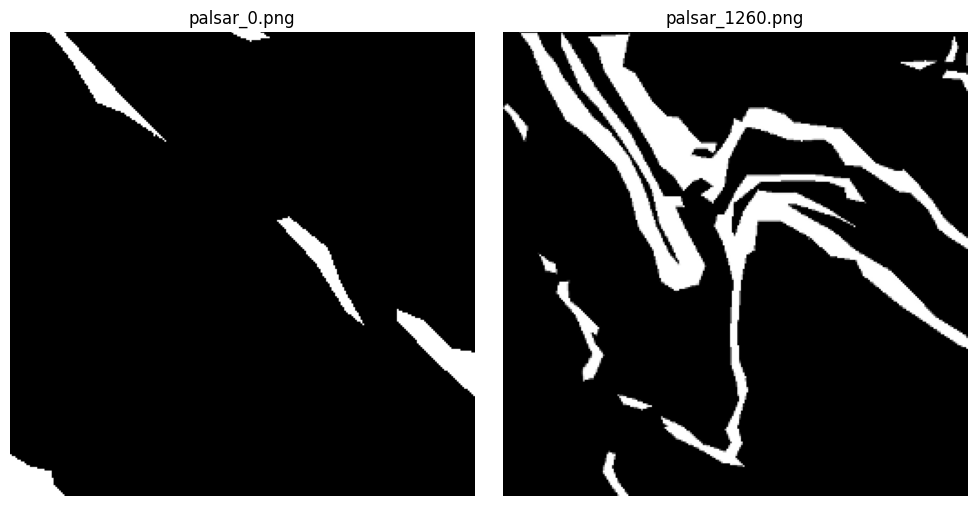

In [7]:

examples = [mask_files[0]]

if len(non_binary) > 0:
    examples.append(
        mask_dir / non_binary.iloc[0]["filename"]
    )

fig, axes = plt.subplots(1, len(examples), figsize=(10, 5))
axes = np.atleast_1d(axes)

for ax, p in zip(axes, examples):
    with Image.open(p) as mask:
        ax.imshow(mask, cmap="gray")

    ax.set_title(p.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


Save final reports

In [8]:

report_dir = dataset.parent / "audit_reports"
report_dir.mkdir(exist_ok=True)

df.to_csv(report_dir / "full_mask_analysis.csv", index=False)
non_binary.to_csv(report_dir / "non_binary_masks.csv", index=False)

print("Mask analysis completed.")
print("Reports saved in:", report_dir)


Mask analysis completed.
Reports saved in: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\dataset\audit_reports
